# Proyecto AFORE, 00: limpieza y exploración de los datos

Datos de CONSAR sobre los rendimientos de las AFORE (archivo `10_rendimientos_precio_bolsa.csv`). Antes de analizar nada quiero entender cómo vienen los datos y arreglar lo que esté mal.

Cada fila dice: en este mes, esta AFORE, en el fondo de esta generación, ganó X% en este plazo. Los plazos (12, 24, 36 meses y 5 años) miran hacia atrás desde cada mes, así que un mes y el siguiente comparten casi todo su periodo. Por eso los meses consecutivos no son datos independientes y voy a comparar rankings y mínimos en lugar de hacer pruebas estadísticas.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
os.makedirs("../images/00", exist_ok=True)

DATA_PATH = "../data/10_rendimientos_precio_bolsa.csv"

PLAZOS = ["12 meses", "24 meses", "36 meses", "5 años"]
AFORES = ["azteca", "banamex", "coppel", "inbursa", "invercap",
          "pensionissste", "principal", "profuturo", "sura", "xxi banorte"]

def guardar(nombre):
    plt.savefig(f"../images/00/{nombre}.png", dpi=150, bbox_inches="tight")

## 1. Cómo viene el archivo

In [2]:
raw = pd.read_csv(DATA_PATH)
print("filas y columnas:", raw.shape)
display(raw.head())
print(raw.dtypes)

filas y columnas: (38179, 5)


,fecha,tipo_recurso,plazo,afore,monto
0,2019-12-01,sb pensiones promedio ponderado,12 meses,sb pensiones promedio ponderado,7.1740
1,2020-01-01,sb pensiones promedio ponderado,12 meses,sb pensiones promedio ponderado,7.4482
2,2020-02-01,sb pensiones promedio ponderado,12 meses,sb pensiones promedio ponderado,7.6127
3,2020-03-01,sb pensiones promedio ponderado,12 meses,sb pensiones promedio ponderado,6.7287
4,2020-04-01,sb pensiones promedio ponderado,12 meses,sb pensiones promedio ponderado,6.9632


fecha               str
tipo_recurso        str
plazo               str
afore               str
monto           float64
dtype: object


In [3]:
print(raw["tipo_recurso"].value_counts().to_string())
print()
print(raw["plazo"].value_counts().to_string())
print()
print("valores distintos en afore:", raw["afore"].nunique())
print(sorted(raw["afore"].unique()))

tipo_recurso
adicionales promedio ponderado     5256
sb 60-64 promedio ponderado        4015
sb pensiones promedio ponderado    3212
sb 65-69 promedio ponderado        3212
sb 70-74 promedio ponderado        3212
sb 75-79 promedio ponderado        3212
sb 80-84 promedio ponderado        3212
sb 85-89 promedio ponderado        3212
sb 90-94 promedio ponderado        3212
sb 1000 promedio ponderado         3212
sb 55-59 promedio ponderado        2464
sb 95-99 promedio ponderado         748

plazo
12 meses     9344
24 meses     9344
36 meses     9344
5 años       9344
historico     803

valores distintos en afore: 39
['adicionales promedio ponderado', 'azteca', 'banamex', 'banamex (siav2)', 'coppel', 'inbursa', 'invercap', 'pensionissste', 'principal', 'profuturo', 'profuturo (sac)', 'profuturo (siav)', 'sb 1000 promedio ponderado', 'sb 55-59 promedio ponderado', 'sb 60-64 promedio ponderado', 'sb 65-69 promedio ponderado', 'sb 70-74 promedio ponderado', 'sb 75-79 promedio ponderado', 'sb

Son 5 columnas en formato largo: una fila por mes, AFORE, fondo y plazo. La fecha viene como texto. La columna `afore` tiene 39 valores porque mezcla las 10 AFOREs con subfondos de ahorro voluntario (por ejemplo `xxi-banorte (sps3)`) y con filas de promedio del sistema.

## 2. Calidad de los datos

In [4]:
print("nulos:", int(raw.isna().sum().sum()))
print("duplicados (misma fecha, fondo, plazo y afore):",
      int(raw.duplicated(["fecha", "tipo_recurso", "plazo", "afore"]).sum()))

fechas = pd.to_datetime(raw["fecha"])
print("periodo:", fechas.min().date(), "a", fechas.max().date(),
      "| meses distintos:", fechas.nunique(), "| dia del mes:", fechas.dt.day.unique())

nulos: 0
duplicados (misma fecha, fondo, plazo y afore): 0
periodo: 2019-12-01 a 2025-12-01 | meses distintos: 73 | dia del mes: [1]


Reviso si la tabla está completa. Para cada fondo las filas esperadas son meses por entidades por plazos, y si coinciden con las reales no falta nada.

In [5]:
chk = raw.groupby("tipo_recurso").agg(
    filas=("monto", "size"),
    meses=("fecha", "nunique"),
    entidades=("afore", "nunique"),
    plazos=("plazo", "nunique"),
)
chk["esperadas"] = chk["meses"] * chk["entidades"] * chk["plazos"]
chk["cuadra"] = chk["filas"] == chk["esperadas"]
chk

,filas,meses,entidades,plazos,esperadas,cuadra
tipo_recurso,,,,,,
adicionales promedio ponderado,5256,73,18,4,5256,True
sb 1000 promedio ponderado,3212,73,11,4,3212,True
sb 55-59 promedio ponderado,2464,56,11,4,2464,True
sb 60-64 promedio ponderado,4015,73,11,5,4015,True
sb 65-69 promedio ponderado,3212,73,11,4,3212,True
sb 70-74 promedio ponderado,3212,73,11,4,3212,True
sb 75-79 promedio ponderado,3212,73,11,4,3212,True
sb 80-84 promedio ponderado,3212,73,11,4,3212,True
sb 85-89 promedio ponderado,3212,73,11,4,3212,True


Un rendimiento de exactamente 0.00% es raro en inversiones reales. Veo dónde aparecen los ceros.

In [6]:
ceros = raw[raw["monto"] == 0]
print("total de ceros:", len(ceros))
display(ceros.groupby(["tipo_recurso", "plazo"]).size().rename("filas").to_frame())
print("AFOREs con ceros en el plazo historico de la SB 60-64:")
print(sorted(ceros[ceros["plazo"] == "historico"]["afore"].unique()))

total de ceros: 426


,,filas
tipo_recurso,plazo,
adicionales promedio ponderado,5 años,2
sb 60-64 promedio ponderado,historico,292
sb pensiones promedio ponderado,5 años,132


AFOREs con ceros en el plazo historico de la SB 60-64:
['azteca', 'coppel', 'invercap', 'pensionissste']


Ahora los valores negativos y los extremos, para ver si son errores o cosas que de verdad pasaron.

In [7]:
print("valores negativos:", int((raw["monto"] < 0).sum()), f"({(raw['monto'] < 0).mean():.1%})")
neg = raw[raw["monto"] < 0].copy()
neg["mes"] = pd.to_datetime(neg["fecha"]).dt.to_period("M")
print("meses con más negativos:")
print(neg["mes"].value_counts().head(8).sort_index().to_string())

print("\nlos cinco más altos:")
display(raw.nlargest(5, "monto"))
print("los cinco más bajos:")
display(raw.nsmallest(5, "monto"))

valores negativos: 1233 (3.2%)
meses con más negativos:
mes
2022-06     87
2022-08     97
2022-09    138
2022-10    111
2022-11    102
2022-12    109
2023-02     81
2023-10     71
Freq: M

los cinco más altos:


,fecha,tipo_recurso,plazo,afore,monto
4792,2021-03-01,sb 80-84 promedio ponderado,12 meses,banamex,27.1712
5595,2021-03-01,sb 85-89 promedio ponderado,12 meses,banamex,27.0887
7899,2021-03-01,sb 1000 promedio ponderado,12 meses,sura,26.7533
6398,2021-03-01,sb 90-94 promedio ponderado,12 meses,banamex,26.7377
8921,2021-03-01,adicionales promedio ponderado,12 meses,xxi-banorte (sps5),26.4419


los cinco más bajos:


,fecha,tipo_recurso,plazo,afore,monto
5613,2022-09-01,sb 85-89 promedio ponderado,12 meses,banamex,-11.4729
6416,2022-09-01,sb 90-94 promedio ponderado,12 meses,banamex,-11.4473
4810,2022-09-01,sb 80-84 promedio ponderado,12 meses,banamex,-11.3257
7406,2022-09-01,sb 1000 promedio ponderado,12 meses,banamex,-11.0743
5614,2022-10-01,sb 85-89 promedio ponderado,12 meses,banamex,-10.8841


No hay nulos ni duplicados y la tabla está completa. Los negativos se concentran en 2022 y el valor más alto es de marzo de 2021, justo un año después del desplome de marzo de 2020, así que son cosas reales y no errores. Lo que sí hay que arreglar son los ceros: siguen un patrón (4 AFOREs por 73 meses en el plazo histórico, y 12 meses en el plazo de 5 años de la SB de pensiones) que no parece un rendimiento real sino un dato que falta. Falta confirmarlo en el diccionario de datos del portal.

## 3. Limpieza

In [8]:
df = raw.copy()

# fecha como fecha de verdad
df["fecha"] = pd.to_datetime(df["fecha"])

# los ceros los trato como dato faltante
n_ceros = int((df["monto"] == 0).sum())
df["monto"] = df["monto"].replace(0, np.nan)
assert df["monto"].isna().sum() == n_ceros

# nombre de la AFORE sin el subfondo: "xxi-banorte (sps1)" queda "xxi banorte"
df["afore_base"] = (df["afore"]
    .str.replace(r"\s*\(.*\)", "", regex=True)
    .str.replace("-", " ", regex=False)
    .str.strip())

# las filas de promedio no son una AFORE, las marco
df["es_promedio"] = df["afore"].str.contains("promedio ponderado")

# "sb 90-94 promedio ponderado" queda como "90-94"
df["fondo"] = (df["tipo_recurso"]
    .str.replace("promedio ponderado", "", regex=False)
    .str.replace("sb ", "", regex=False)
    .str.strip())

# tabla para comparar AFOREs: fondos por generacion, sin promedios, solo las 10 AFOREs
gen = df[df["fondo"].str.match(r"^\d{2}-\d{2}$") & ~df["es_promedio"] & df["afore"].isin(AFORES)].copy()

# tabla del promedio del sistema (generaciones y pensiones)
sistema = df[df["es_promedio"] & (df["fondo"].str.match(r"^\d{2}-\d{2}$") | (df["fondo"] == "pensiones"))].copy()

print("valores vacíos después de limpiar:", int(df["monto"].isna().sum()))
print("AFOREs:", sorted(df.loc[~df["es_promedio"], "afore_base"].unique()))
print("filas en gen:", len(gen), "| fondos:", sorted(gen["fondo"].unique()))
print("filas en sistema:", len(sistema))

valores vacíos después de limpiar: 426
AFOREs: ['azteca', 'banamex', 'coppel', 'inbursa', 'invercap', 'pensionissste', 'principal', 'profuturo', 'sura', 'xxi banorte']
filas en gen: 24090 | fondos: ['55-59', '60-64', '65-69', '70-74', '75-79', '80-84', '85-89', '90-94', '95-99']
filas en sistema: 2701


Comparo siempre dentro de una misma generación. Cada una invierte con un nivel de riesgo distinto, y si mezclo la de 60 años con la de 25 estaría comparando edades y no AFOREs.

## 4. Cómo se distribuyen los rendimientos

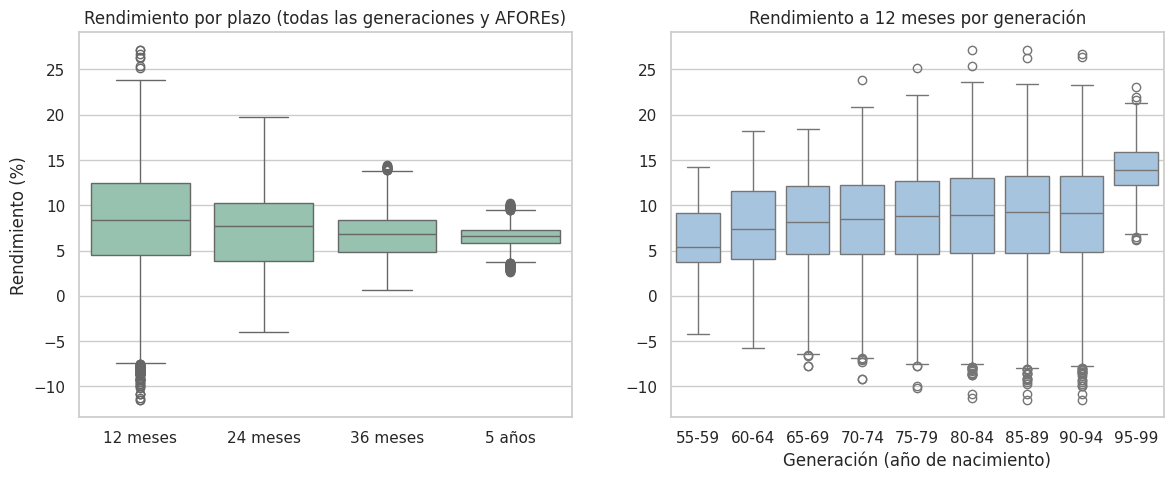

,count,min,median,mean,max
plazo,,,,,
12 meses,5840,-11.47,8.39,7.98,27.17
24 meses,5840,-4.02,7.72,7.26,19.77
36 meses,5840,0.69,6.81,6.75,14.50
5 años,5840,2.67,6.59,6.57,10.22


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=gen, x="plazo", y="monto", order=PLAZOS, ax=axes[0], color="#8fc9b0")
axes[0].set_title("Rendimiento por plazo (todas las generaciones y AFOREs)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Rendimiento (%)")

orden_fondos = sorted(gen["fondo"].unique())
sns.boxplot(data=gen[gen["plazo"] == "12 meses"], x="fondo", y="monto", order=orden_fondos, ax=axes[1], color="#9ec5e8")
axes[1].set_title("Rendimiento a 12 meses por generación")
axes[1].set_xlabel("Generación (año de nacimiento)")
axes[1].set_ylabel("")
guardar("01_distribucion")
plt.show()

gen.groupby("plazo")["monto"].agg(["count", "min", "median", "mean", "max"]).reindex(PLAZOS).round(2)

Mientras más largo el plazo, menos variación, lo cual tiene sentido porque al promediar varios años se suavizan los sustos. Y las generaciones más jóvenes tienen cajas más altas y más anchas: pueden ganar más pero también se mueven más.

## 5. Evolución en el tiempo y riesgo por generación

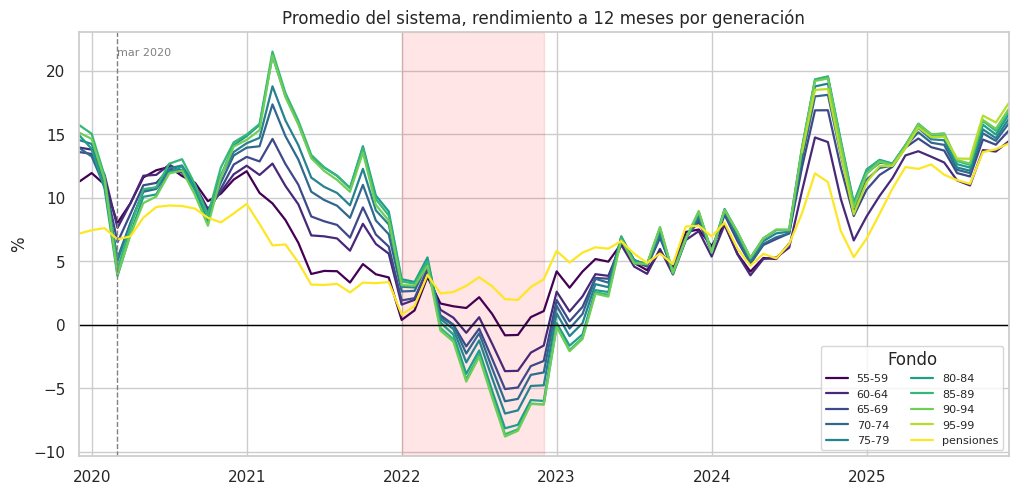

In [10]:
s12 = sistema[sistema["plazo"] == "12 meses"].pivot(index="fecha", columns="fondo", values="monto")

fig, ax = plt.subplots(figsize=(12, 5.5))
s12.plot(ax=ax, lw=1.6, colormap="viridis")
ax.axhline(0, color="black", lw=1)
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), alpha=0.1, color="red")
ax.axvline(pd.Timestamp("2020-03-01"), color="gray", ls="--", lw=1)
ax.text(pd.Timestamp("2020-03-10"), ax.get_ylim()[1] * 0.92, "mar 2020", fontsize=8, color="gray")
ax.set_title("Promedio del sistema, rendimiento a 12 meses por generación")
ax.set_ylabel("%")
ax.set_xlabel("")
ax.legend(title="Fondo", ncol=2, fontsize=8)
guardar("02_evolucion_sistema_12m")
plt.show()

,fecha_ultimo_dato,ultimo_12m,mes_del_peor,peor_12m
fondo,,,,
55-59,2024-07,6.39,2022-09,-0.83
60-64,2025-12,14.45,2022-09,-3.65
65-69,2025-12,15.29,2022-09,-5.06
70-74,2025-12,15.85,2022-09,-6.02
75-79,2025-12,16.20,2022-09,-6.99
80-84,2025-12,16.56,2022-09,-8.15
85-89,2025-12,16.87,2022-09,-8.62
90-94,2025-12,16.99,2022-09,-8.80
95-99,2025-12,17.45,2024-12,8.70


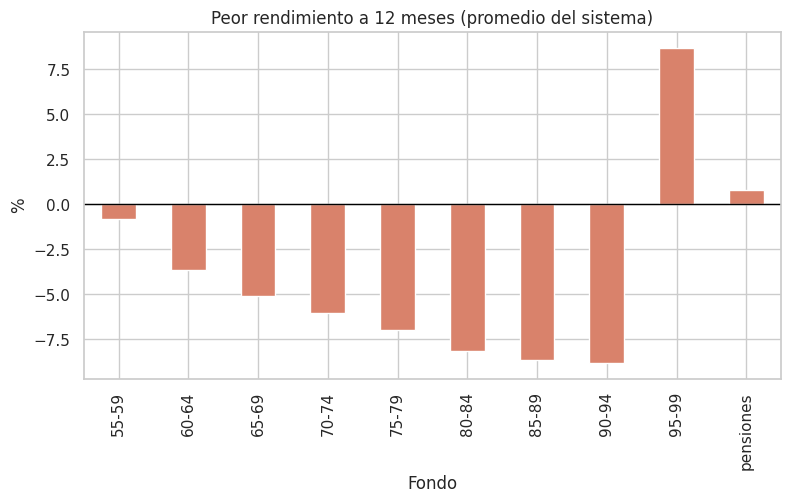

In [11]:
# por fondo: último dato y peor momento a 12 meses
sis12 = sistema[sistema["plazo"] == "12 meses"]
ultimo = sis12.sort_values("fecha").groupby("fondo").tail(1).set_index("fondo")[["fecha", "monto"]]
ultimo.columns = ["fecha_ultimo_dato", "ultimo_12m"]
idx_peor = sis12.groupby("fondo")["monto"].idxmin()
peor = sis12.loc[idx_peor].set_index("fondo")[["fecha", "monto"]]
peor.columns = ["mes_del_peor", "peor_12m"]
riesgo = ultimo.join(peor).sort_index()
riesgo["fecha_ultimo_dato"] = riesgo["fecha_ultimo_dato"].dt.strftime("%Y-%m")
riesgo["mes_del_peor"] = riesgo["mes_del_peor"].dt.strftime("%Y-%m")
display(riesgo.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
riesgo["peor_12m"].plot(kind="bar", ax=ax, color="#d9826b")
ax.axhline(0, color="black", lw=1)
ax.set_title("Peor rendimiento a 12 meses (promedio del sistema)")
ax.set_xlabel("Fondo")
ax.set_ylabel("%")
guardar("03_peor_12m_por_fondo")
plt.show()

La SB 95-99 solo existe desde agosto de 2024, así que su peor momento no incluye 2022 y no se puede comparar con las demás. La SB 55-59 termina en julio de 2024. Para ver la relación entre edad y riesgo hay que fijarse en las generaciones que sí cubren 2022.

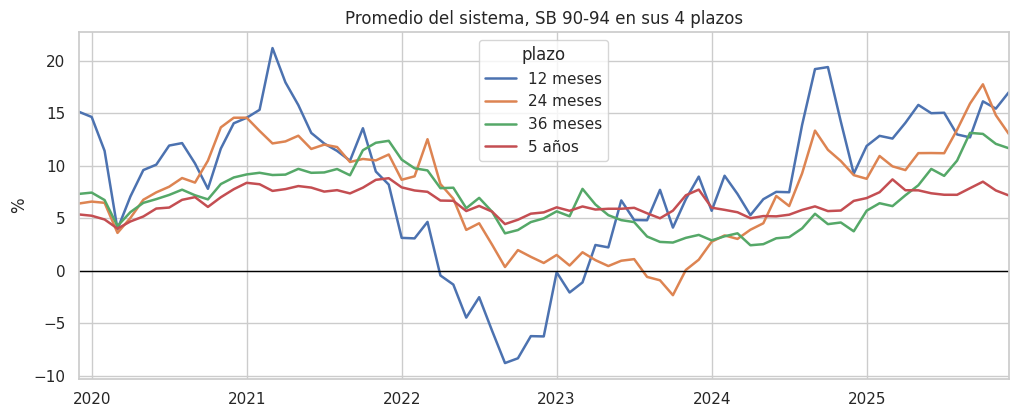

In [12]:
# el mismo fondo (90-94) en sus 4 plazos
p90 = sistema[sistema["fondo"] == "90-94"].pivot(index="fecha", columns="plazo", values="monto")[PLAZOS]
ax = p90.plot(figsize=(12, 4.5), lw=1.8)
ax.axhline(0, color="black", lw=1)
ax.set_title("Promedio del sistema, SB 90-94 en sus 4 plazos")
ax.set_ylabel("%")
ax.set_xlabel("")
guardar("04_plazos_sb9094")
plt.show()

Los plazos largos son una versión suavizada del de 12 meses: se mueven más despacio y casi nunca cruzan el cero.

## 6. Comparación entre AFOREs (generación 90-94)
Para repetir todo con otra generación basta cambiar `GEN` (por ejemplo "85-89" para alguien nacido en 1985).

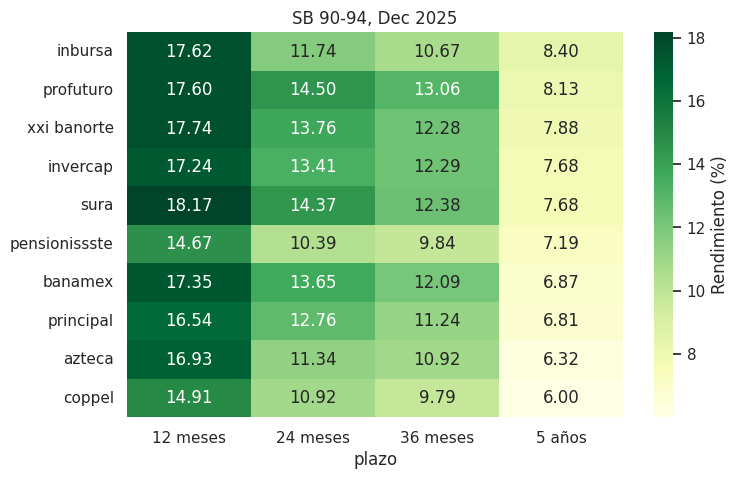

In [13]:
GEN = "90-94"
g = gen[gen["fondo"] == GEN]
w = (g.pivot_table(index=["fecha", "afore"], columns="plazo", values="monto")[PLAZOS]
       .reset_index())
ultima = w["fecha"].max()

rank_hoy = w[w["fecha"] == ultima].set_index("afore")[PLAZOS].sort_values("5 años", ascending=False)
plt.figure(figsize=(8, 5))
sns.heatmap(rank_hoy, annot=True, fmt=".2f", cmap="YlGn", cbar_kws={"label": "Rendimiento (%)"})
plt.title(f"SB {GEN}, {ultima:%b %Y}")
plt.ylabel("")
guardar("05_heatmap_hoy")
plt.show()

### 6.1 Qué tan distintas son entre sí
Diferencia entre la mejor y la peor AFORE en cada mes, en puntos porcentuales.

plazo,12 meses,24 meses,36 meses,5 años
min,2.50,1.89,1.79,1.44
mean,5.92,4.12,2.81,2.31
max,13.79,6.69,4.58,3.49


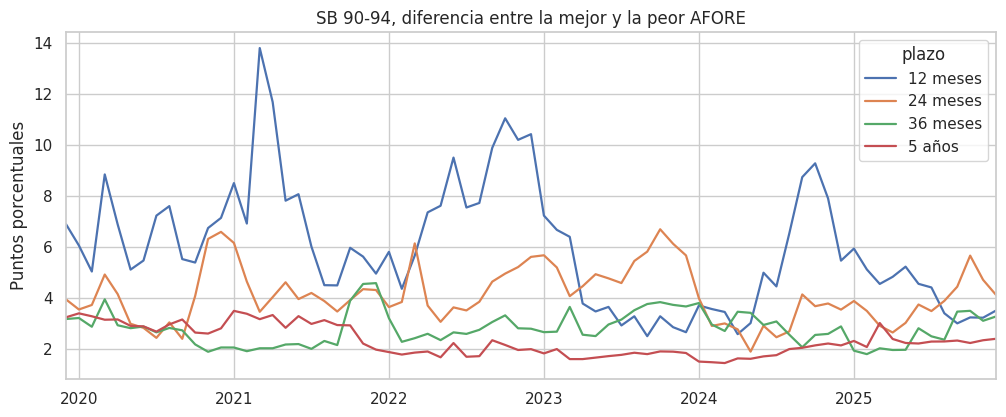

In [14]:
dispersion = w.groupby("fecha")[PLAZOS].agg(lambda s: s.max() - s.min())
display(dispersion.describe().loc[["min", "mean", "max"]].round(2))

ax = dispersion.plot(figsize=(12, 4.5), lw=1.6)
ax.set_title(f"SB {GEN}, diferencia entre la mejor y la peor AFORE")
ax.set_ylabel("Puntos porcentuales")
ax.set_xlabel("")
guardar("06_dispersion")
plt.show()

### 6.2 Quién va arriba y quién abajo

meses analizados: 73 (lider y ultimo cuentan cuántos meses fue primera o última)


,lider_12m,ultimo_12m,lider_5a,ultimo_5a,posicion_prom_12m,variacion_12m,posicion_prom_5a,variacion_5a
afore,,,,,,,,
profuturo,13,0,33,0,4.2,2.4,2.2,1.2
xxi banorte,3,0,2,0,4.2,1.6,3.6,1.4
inbursa,18,18,12,1,5.7,3.6,3.8,2.3
sura,10,2,4,1,5.1,2.9,4.3,2.0
pensionissste,8,7,17,13,5.9,3.3,5.4,3.3
principal,2,10,0,0,6.3,2.7,6.1,1.1
invercap,10,0,5,13,4.2,2.1,7.0,2.9
banamex,7,9,0,1,5.3,3.0,7.1,1.5
coppel,0,18,0,20,7.3,2.4,7.3,2.8


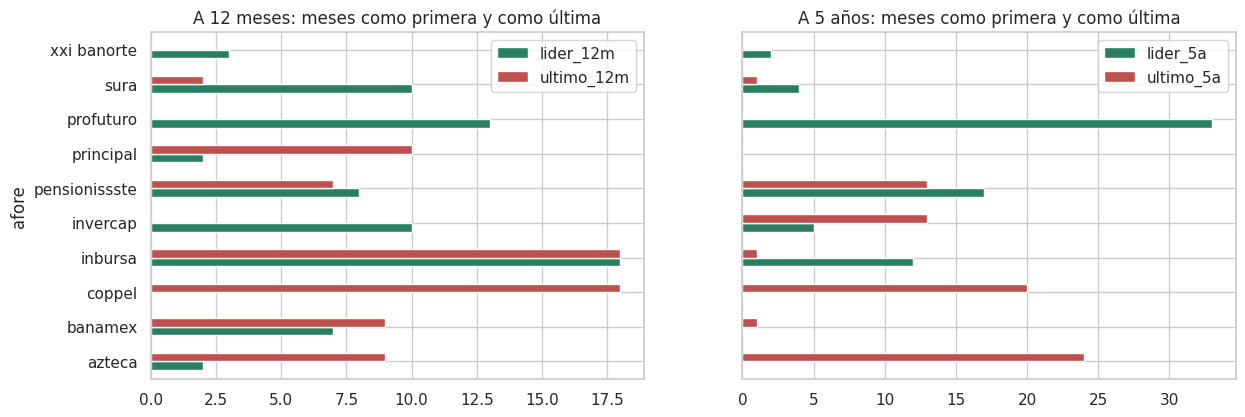

In [15]:
# posición de cada AFORE en cada mes (1 es la mejor)
w["rank_12m"] = w.groupby("fecha")["12 meses"].rank(ascending=False)
w["rank_5a"] = w.groupby("fecha")["5 años"].rank(ascending=False)

def veces(col, f):
    idx = w.groupby("fecha")[col].agg(f)
    return w.loc[idx, "afore"].value_counts()

podio = pd.DataFrame({
    "lider_12m": veces("12 meses", "idxmax"),
    "ultimo_12m": veces("12 meses", "idxmin"),
    "lider_5a": veces("5 años", "idxmax"),
    "ultimo_5a": veces("5 años", "idxmin"),
}).reindex(AFORES).fillna(0).astype(int)
podio["posicion_prom_12m"] = w.groupby("afore")["rank_12m"].mean().round(1)
podio["variacion_12m"] = w.groupby("afore")["rank_12m"].std().round(1)
podio["posicion_prom_5a"] = w.groupby("afore")["rank_5a"].mean().round(1)
podio["variacion_5a"] = w.groupby("afore")["rank_5a"].std().round(1)
print("meses analizados:", w["fecha"].nunique(), "(lider y ultimo cuentan cuántos meses fue primera o última)")
display(podio.sort_values("posicion_prom_5a"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
podio[["lider_12m", "ultimo_12m"]].plot(kind="barh", ax=axes[0], color=["#2a7f62", "#c0504d"])
axes[0].set_title("A 12 meses: meses como primera y como última")
podio[["lider_5a", "ultimo_5a"]].plot(kind="barh", ax=axes[1], color=["#2a7f62", "#c0504d"])
axes[1].set_title("A 5 años: meses como primera y como última")
guardar("07_podio")
plt.show()

### 6.3 Rendimiento y estabilidad a 12 meses

,promedio,desv_estandar,peor,mejor
afore,,,,
profuturo,9.07,7.21,-8.07,22.70
xxi banorte,8.95,7.17,-9.34,21.10
invercap,8.89,7.08,-8.56,20.35
sura,8.87,8.02,-9.92,26.42
banamex,8.50,8.47,-11.45,26.74
pensionissste,8.34,4.54,-2.15,16.00
principal,8.24,7.56,-9.92,20.63
inbursa,8.11,4.01,-1.57,17.62
azteca,7.33,6.14,-8.39,16.93


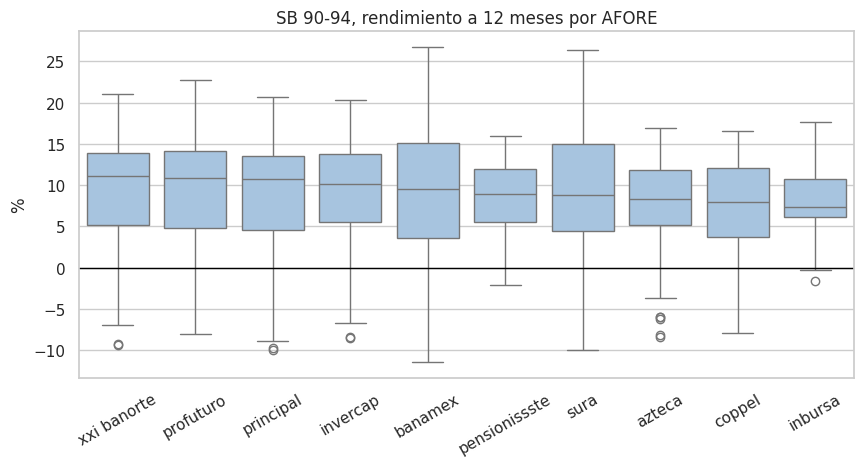

In [16]:
est = (g[g["plazo"] == "12 meses"].groupby("afore")["monto"]
         .agg(promedio="mean", desv_estandar="std", peor="min", mejor="max")
         .sort_values("promedio", ascending=False))
display(est.round(2))

orden = g[g["plazo"] == "12 meses"].groupby("afore")["monto"].median().sort_values(ascending=False).index
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=g[g["plazo"] == "12 meses"], x="afore", y="monto", order=orden, color="#9ec5e8")
plt.axhline(0, color="black", lw=1)
plt.title(f"SB {GEN}, rendimiento a 12 meses por AFORE")
plt.xlabel("")
plt.ylabel("%")
plt.xticks(rotation=30)
guardar("08_boxplot_afores")
plt.show()

## 7. Los plazos entre sí
Esto es solo descriptivo. Como las ventanas se traslapan no lo uso como prueba de nada.

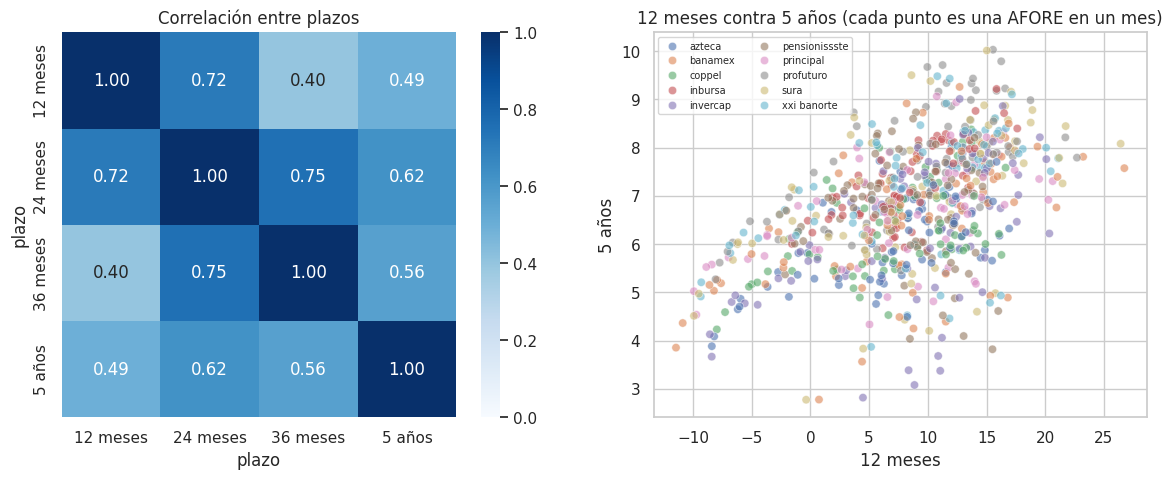

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(w[PLAZOS].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Correlación entre plazos")
sns.scatterplot(data=w, x="12 meses", y="5 años", hue="afore", alpha=0.6, ax=axes[1])
axes[1].set_title("12 meses contra 5 años (cada punto es una AFORE en un mes)")
axes[1].legend(fontsize=7, ncol=2)
guardar("09_plazos")
plt.show()

## 8. Lo mismo en las otras generaciones
Repito las medidas principales en cada generación para ver si lo de la 90-94 es general o solo de esa.

In [18]:
filas = []
for f, sub in gen.groupby("fondo"):
    p = sub.pivot_table(index=["fecha", "afore"], columns="plazo", values="monto")[PLAZOS].reset_index()
    disp = p.groupby("fecha")[PLAZOS].agg(lambda s: s.max() - s.min())
    sp = pd.Series({d: spearmanr(x["12 meses"], x["5 años"])[0] for d, x in p.groupby("fecha")})
    lid = p.loc[p.groupby("fecha")["5 años"].idxmax(), "afore"].value_counts()
    ult = p.loc[p.groupby("fecha")["5 años"].idxmin(), "afore"].value_counts()
    filas.append({
        "fondo": f, "meses": p["fecha"].nunique(),
        "diferencia_12m": disp["12 meses"].mean(), "diferencia_5a": disp["5 años"].mean(),
        "spearman_12m_vs_5a": sp.mean(),
        "lider_5a": lid.index[0], "meses_lider": int(lid.iloc[0]),
        "ultimo_5a": ult.index[0], "meses_ultimo": int(ult.iloc[0]),
    })
robustez = pd.DataFrame(filas).set_index("fondo")
robustez.round(2)

,meses,diferencia_12m,diferencia_5a,spearman_12m_vs_5a,lider_5a,meses_lider,ultimo_5a,meses_ultimo
fondo,,,,,,,,
55-59,56,3.60,1.48,0.40,inbursa,40,invercap,31
60-64,73,4.60,2.05,0.32,profuturo,23,banamex,43
65-69,73,4.57,2.02,0.32,pensionissste,30,coppel,35
70-74,73,5.16,2.05,0.42,profuturo,44,invercap,40
75-79,73,5.49,2.17,0.44,profuturo,52,invercap,42
80-84,73,5.82,2.29,0.42,profuturo,41,azteca,35
85-89,73,5.90,2.38,0.39,profuturo,43,invercap,31
90-94,73,5.92,2.31,0.37,profuturo,33,azteca,24
95-99,17,5.64,2.47,0.65,profuturo,7,coppel,17


Un Spearman cercano a 1 quiere decir que la AFORE que gana a 12 meses suele ser la que gana a 5 años, y cerca de 0 que el corto plazo casi no dice nada del largo. La SB 95-99 tiene pocos meses (desde agosto de 2024), así que no es comparable.

## 9. Series que dejo fuera: adicionales y sb 1000

In [19]:
ad = df[df["fondo"] == "adicionales"]
print("entidades en adicionales:", ad["afore"].nunique())
print(sorted(ad["afore"].unique()))
display(ad.groupby("plazo")["monto"].describe().reindex(PLAZOS).round(2))

entidades en adicionales: 18
['adicionales promedio ponderado', 'banamex (siav2)', 'profuturo (sac)', 'profuturo (siav)', 'sura (siav)', 'sura (siav1)', 'sura (siav2)', 'xxi-banorte (siav)', 'xxi-banorte (sps1)', 'xxi-banorte (sps10)', 'xxi-banorte (sps2)', 'xxi-banorte (sps3)', 'xxi-banorte (sps4)', 'xxi-banorte (sps5)', 'xxi-banorte (sps6)', 'xxi-banorte (sps7)', 'xxi-banorte (sps8)', 'xxi-banorte (sps9)']


,count,mean,std,min,25%,50%,75%,max
plazo,,,,,,,,
12 meses,1314.0,8.43,5.40,-9.60,5.08,9.08,12.35,26.44
24 meses,1314.0,7.75,3.95,-3.06,4.75,7.90,10.70,20.40
36 meses,1314.0,7.23,2.48,-0.30,5.56,7.11,8.84,14.66
5 años,1312.0,6.89,1.29,3.26,5.90,6.87,7.91,11.42


Las adicionales son el ahorro voluntario. Traen muchos subfondos por AFORE (por ejemplo de `sps1` a `sps10` en XXI Banorte) y el archivo no los explica, así que no las mezclo con el análisis por generación.

correlación entre ambas: 0.997
diferencia (sb_1000 menos sb_90_94):
count    73.00
mean     -0.39
std       0.54
min      -1.64
25%      -0.82
50%      -0.21
75%       0.01
max       0.53


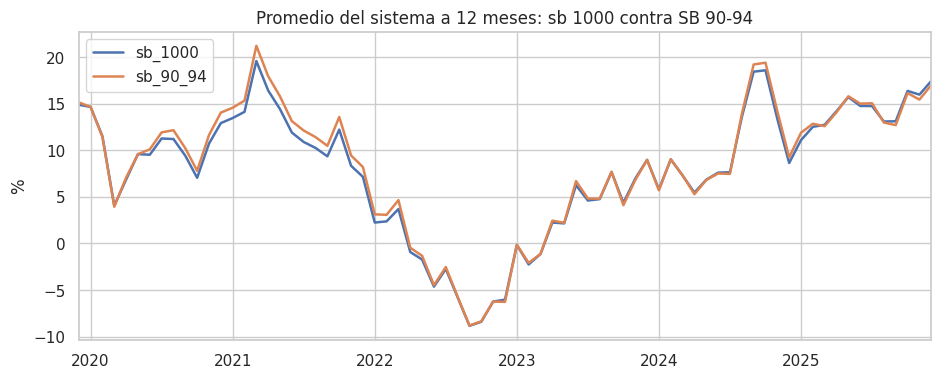

In [20]:
a = df[(df["fondo"] == "1000") & df["es_promedio"] & (df["plazo"] == "12 meses")].set_index("fecha")["monto"]
b = df[(df["fondo"] == "90-94") & df["es_promedio"] & (df["plazo"] == "12 meses")].set_index("fecha")["monto"]
comp = pd.concat([a.rename("sb_1000"), b.rename("sb_90_94")], axis=1)

print("correlación entre ambas:", round(comp.corr().iloc[0, 1], 3))
print("diferencia (sb_1000 menos sb_90_94):")
print((comp["sb_1000"] - comp["sb_90_94"]).describe().round(2).to_string())

ax = comp.plot(figsize=(11, 4), lw=1.8)
ax.set_title("Promedio del sistema a 12 meses: sb 1000 contra SB 90-94")
ax.set_xlabel("")
ax.set_ylabel("%")
guardar("10_sb1000_vs_9094")
plt.show()

La serie `sb 1000` se mueve casi igual que las generaciones jóvenes, pero no sé qué representa. La dejo fuera hasta confirmarlo en el diccionario de datos.

## Qué encontré

La base está limpia: 38,179 filas, sin nulos ni duplicados, 73 meses (dic 2019 a dic 2025) y sin huecos en ninguno de los 12 fondos. Lo único raro son 426 ceros exactos (292 en el plazo histórico de la SB 60-64 para Azteca, Coppel, Invercap y PensionISSSTE, 132 en el plazo de 5 años de la SB de pensiones y 2 en adicionales) que traté como dato faltante. Hay 1,233 valores negativos (3.2%), casi todos en 2022, y septiembre de 2022 es el mes con más (138).

Sobre riesgo y edad: mientras más joven la generación, más profunda fue la caída de 2022. El peor rendimiento a 12 meses del promedio del sistema (siempre en septiembre de 2022) va de -0.83% en la SB 55-59 y -3.65% en la SB 60-64 hasta -8.80% en la SB 90-94. El fondo de pensiones nunca cayó (su mínimo fue 0.80%). En el buen momento pasa lo contrario: a dic 2025 los fondos jóvenes rinden más a 12 meses (14.27% pensiones, 14.45% SB 60-64, 16.99% SB 90-94). Y mientras más largo el plazo, menos variación: a 12 meses los rendimientos van de -11.47% a 27.17% y a 5 años de 2.67% a 10.22%.

Entre AFOREs, en la SB 90-94, la diferencia entre la mejor y la peor es de 5.9 puntos en promedio a 12 meses (hasta 13.8 en marzo de 2021) y de 2.3 puntos a 5 años. A 5 años Profuturo fue la primera en 33 de 73 meses, con posición promedio de 2.2 y nunca última. Azteca fue última en 24 meses y Coppel en 20. A 12 meses el ranking cambia mucho: nueve AFOREs distintas fueron primeras en algún mes, e Inbursa fue primera en 18 meses y última en otros 18, aunque tuvo la menor caída (-1.57%) y la menor variación junto con PensionISSSTE (desviación estándar de 4.0 y 4.5, contra 6 a 8.5 del resto). Estos conteos usan ventanas que se traslapan, así que describen el periodo pero no prueban nada.

Los plazos vecinos se parecen (12 y 24 meses, 0.72) y el de 12 meses con el de 36 apenas llega a 0.40. La correlación entre el ranking a 12 meses y el de 5 años promedia entre 0.32 y 0.44 en las generaciones con 56 meses o más, o sea que el corto plazo dice poco del largo plazo en casi todas. Profuturo lidera a 5 años en 7 de las 9 generaciones, y Invercap, Azteca y Coppel son las que más aparecen al fondo.

Sobre las series que dejé fuera: `sb 1000` se mueve casi idéntica a la SB 90-94 (correlación de 0.997, en promedio 0.39 puntos por debajo) y no sé qué es. Las adicionales traen 18 entidades.

Pendiente de confirmar en el diccionario de datos de CONSAR: que el cero signifique "sin dato", qué es `sb 1000`, si el plazo de 5 años viene anualizado y si el `monto` ya descuenta comisiones. Los dos últimos los reviso en los notebooks 03 y 02.